# Phase Unwrapping with Kamui

Kamui's two grid solvers, LEMON (the network-programming ILP) and PUMA (graph cuts), against
scikit-image's `unwrap_phase`, [SNAPHU](https://github.com/isce-framework/snaphu-py) and
[spurs](https://github.com/scottstanie/spurs) on synthetic 2-D phase images.

Each figure starts with the true and the wrapped phase. Every row after that is one method: its
unwrapped phase, shifted by the constant multiple of $2\pi$ that unwrapping cannot recover, and the
pixels it gets wrong, in black. Hatching marks NaN.

In [1]:
import io
import os
import warnings
from contextlib import contextmanager, redirect_stdout
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import snaphu
from skimage import color, data, exposure, img_as_float
from skimage.restoration import unwrap_phase

import kamui

# spurs prints a notice about GDAL on import, which it needs only to read files.
with redirect_stdout(io.StringIO()), warnings.catch_warnings():
    warnings.simplefilter("ignore", SyntaxWarning)
    import spurs

# Seeded, so re-executing the notebook reproduces its figures.
rng = np.random.default_rng(0)

In [2]:
@contextmanager
def quiet_stdout():
    """Silence SNAPHU, whose executable logs to the process's stdout."""
    saved = os.dup(1)
    with open(os.devnull, "w") as devnull:
        os.dup2(devnull.fileno(), 1)
    try:
        yield
    finally:
        os.dup2(saved, 1)
        os.close(saved)


def unwrap_snaphu(wrapped, coherence=None):
    """Unwrap with SNAPHU's smooth-surface cost, masking NaN pixels.

    Without a coherence map, SNAPHU gets a uniform 0.5.
    """
    valid = ~np.isnan(wrapped)
    igram = np.where(valid, np.exp(1j * np.nan_to_num(wrapped)), 0).astype(np.complex64)
    corr = np.full(wrapped.shape, 0.5) if coherence is None else coherence
    with quiet_stdout():
        unwrapped, _ = snaphu.unwrap(
            igram, corr.astype(np.float32), nlooks=1, cost="smooth", mask=valid
        )
    return np.where(valid, unwrapped, np.nan)


def unwrap_spurs(wrapped):
    """Unwrap with spurs, then snap the result to the nearest congruent phase.

    spurs returns a smooth estimate that differs from the wrapped phase by more than whole
    periods; rounding the difference to whole periods makes it an unwrapping of the input.
    """
    smooth = spurs.unwrap(wrapped).astype(float)
    return wrapped + 2 * np.pi * np.round((smooth - wrapped) / (2 * np.pi))


METHODS = {
    "skimage": unwrap_phase,
    "SNAPHU": unwrap_snaphu,
    "spurs": unwrap_spurs,
    # solver="lemon" raises an error instead of falling back to HiGHS.
    "Kamui LEMON": lambda wrapped: kamui.unwrap_dimensional(wrapped, solver="lemon"),
    # PUMA needs `pip install kamui[extra]`.
    "Kamui PUMA": lambda wrapped: kamui.unwrap_dimensional(wrapped, method="gc"),
}


def unwrap_all(wrapped, methods=METHODS):
    """Run every method on `wrapped`."""
    return {name: unwrap(wrapped) for name, unwrap in methods.items()}

In [3]:
def common_offset(unwrapped, truth):
    """Return the most common whole number of periods between `unwrapped` and `truth`."""
    cycles = np.round((unwrapped - truth) / (2 * np.pi))
    values, counts = np.unique(cycles[~np.isnan(cycles)], return_counts=True)
    return values[counts.argmax()]


def cycle_errors(unwrapped, truth):
    """Whole periods by which each pixel misses `truth`, beyond the common offset."""
    return np.round((unwrapped - truth) / (2 * np.pi)) - common_offset(unwrapped, truth)


def n_errors(unwrapped, truth):
    """Count the pixels that land on the wrong multiple of 2π."""
    return int(np.sum(np.abs(cycle_errors(unwrapped, truth)) > 0.5))


def compare(truth, wrapped, results):
    """Plot the true and wrapped phase, then one row per result: it and its wrong pixels."""
    nrows = 1 + len(results)
    height, width = truth.shape
    panel = 2.8
    fig, axes = plt.subplots(
        nrows,
        2,
        figsize=(2 * panel, nrows * (panel * height / width + 0.35)),
        layout="constrained",
    )
    for ax in axes.flat:
        ax.set_xticks([])
        ax.set_yticks([])
        # NaN pixels are transparent, so the hatched background shows through.
        ax.patch.set_hatch("////")
        ax.patch.set_edgecolor("0.7")
    scale = {"cmap": "gray", "vmin": np.nanmin(truth), "vmax": np.nanmax(truth)}
    axes[0, 0].imshow(truth, **scale)
    axes[0, 0].set_title("True phase")
    axes[0, 1].imshow(wrapped, cmap="gray", vmin=-np.pi, vmax=np.pi)
    axes[0, 1].set_title("Wrapped")
    for (left, right), (name, unwrapped) in zip(axes[1:], results.items(), strict=True):
        left.imshow(unwrapped - 2 * np.pi * common_offset(unwrapped, truth), **scale)
        left.set_title(name)
        errors = cycle_errors(unwrapped, truth)
        wrong = np.where(np.isnan(errors), np.nan, np.abs(errors) > 0.5)
        right.imshow(wrong, cmap="gray_r", vmin=0, vmax=1)
        right.set_title(f"{n_errors(unwrapped, truth)} wrong")
    plt.show()

## Plane Wave

A plane wave, without noise and with Gaussian noise of 0.15 periods.

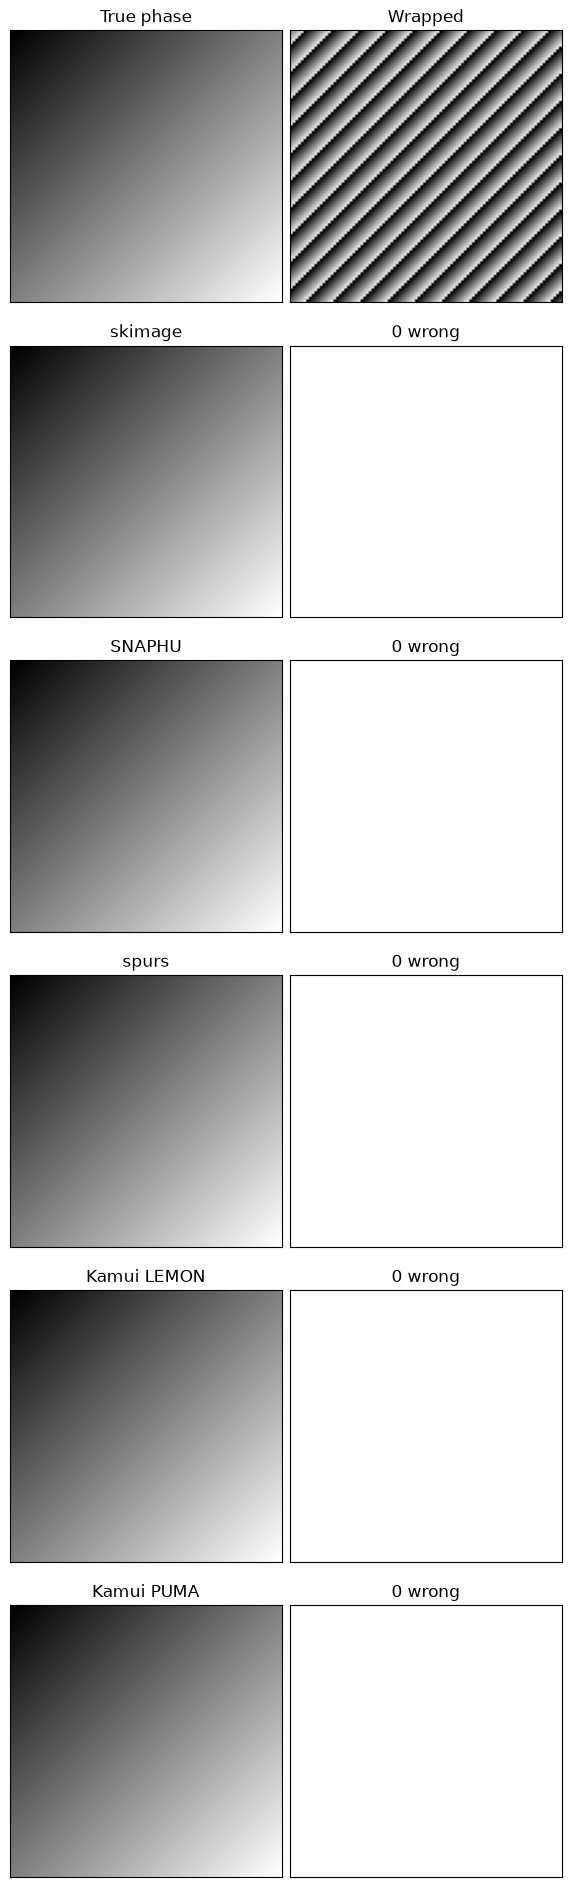

In [4]:
N = 100
yy, xx = np.mgrid[0:N, 0:N]
plane_wave = 0.2 * np.pi * (xx + yy)
wrapped_plane_wave = kamui.wrap_difference(plane_wave)
plane_results = unwrap_all(wrapped_plane_wave)

compare(plane_wave, wrapped_plane_wave, plane_results)

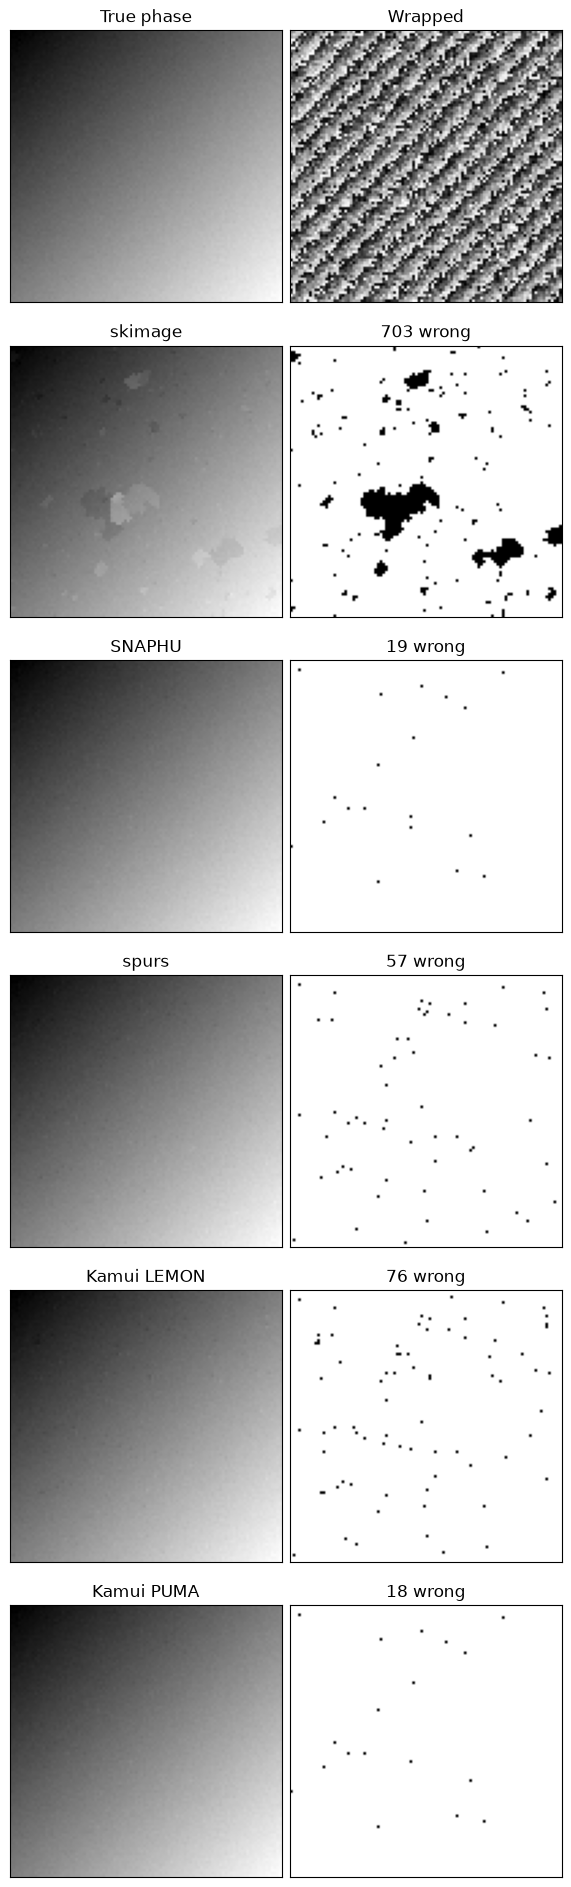

In [5]:
noisy_plane_wave = plane_wave + rng.normal(0, 0.15 * 2 * np.pi, plane_wave.shape)
wrapped_noisy_plane_wave = kamui.wrap_difference(noisy_plane_wave)

compare(noisy_plane_wave, wrapped_noisy_plane_wave, unwrap_all(wrapped_noisy_plane_wave))

## Shear

Two ramps meeting head to head along the middle row, where the phase jumps by up to 60 rad; then
with noise of 0.125 periods.

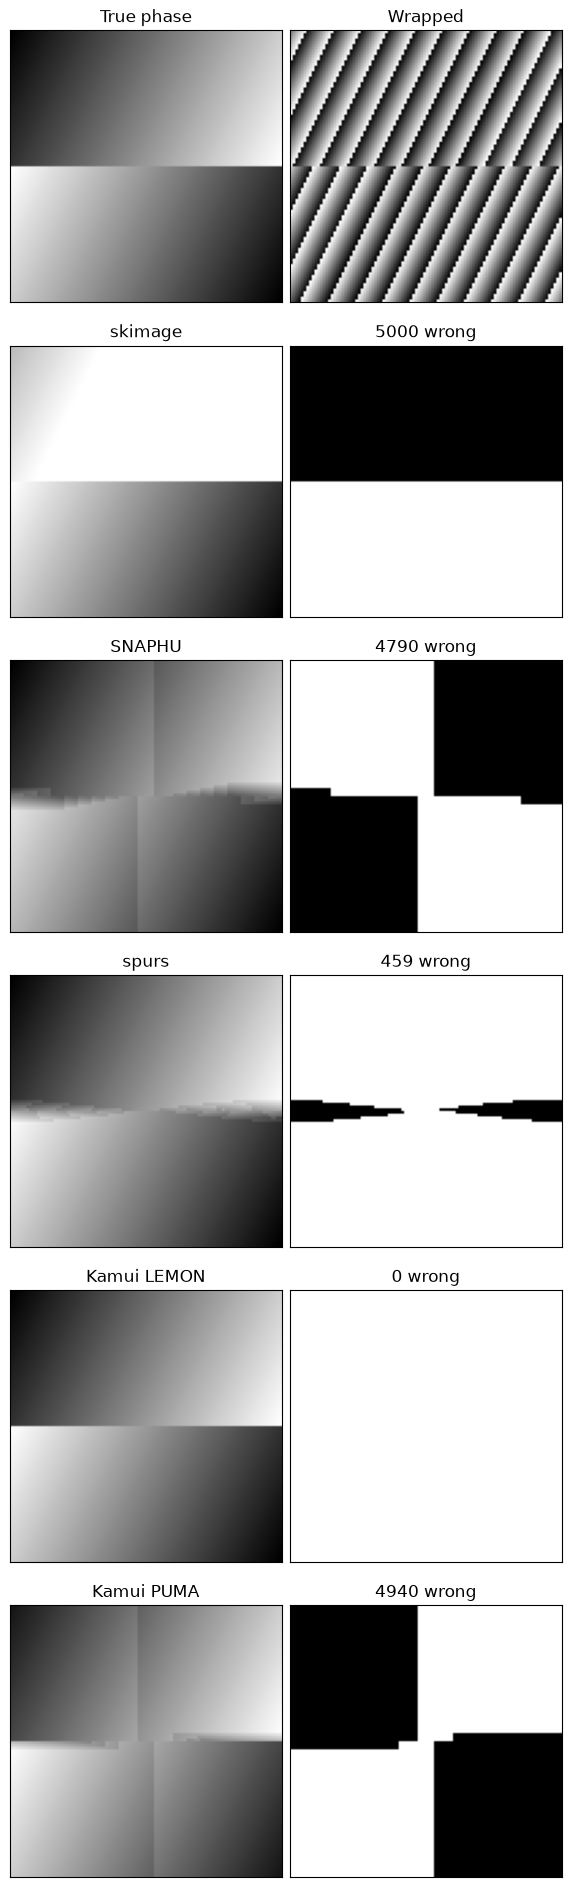

In [6]:
yy2, xx2 = np.mgrid[0:50, 0:100]
ramp = xx2 / 1.6 + yy2 / 3.2
shear = np.concatenate([ramp, ramp[::-1, ::-1]])
wrapped_shear = kamui.wrap_difference(shear)
shear_results = unwrap_all(wrapped_shear)

compare(shear, wrapped_shear, shear_results)

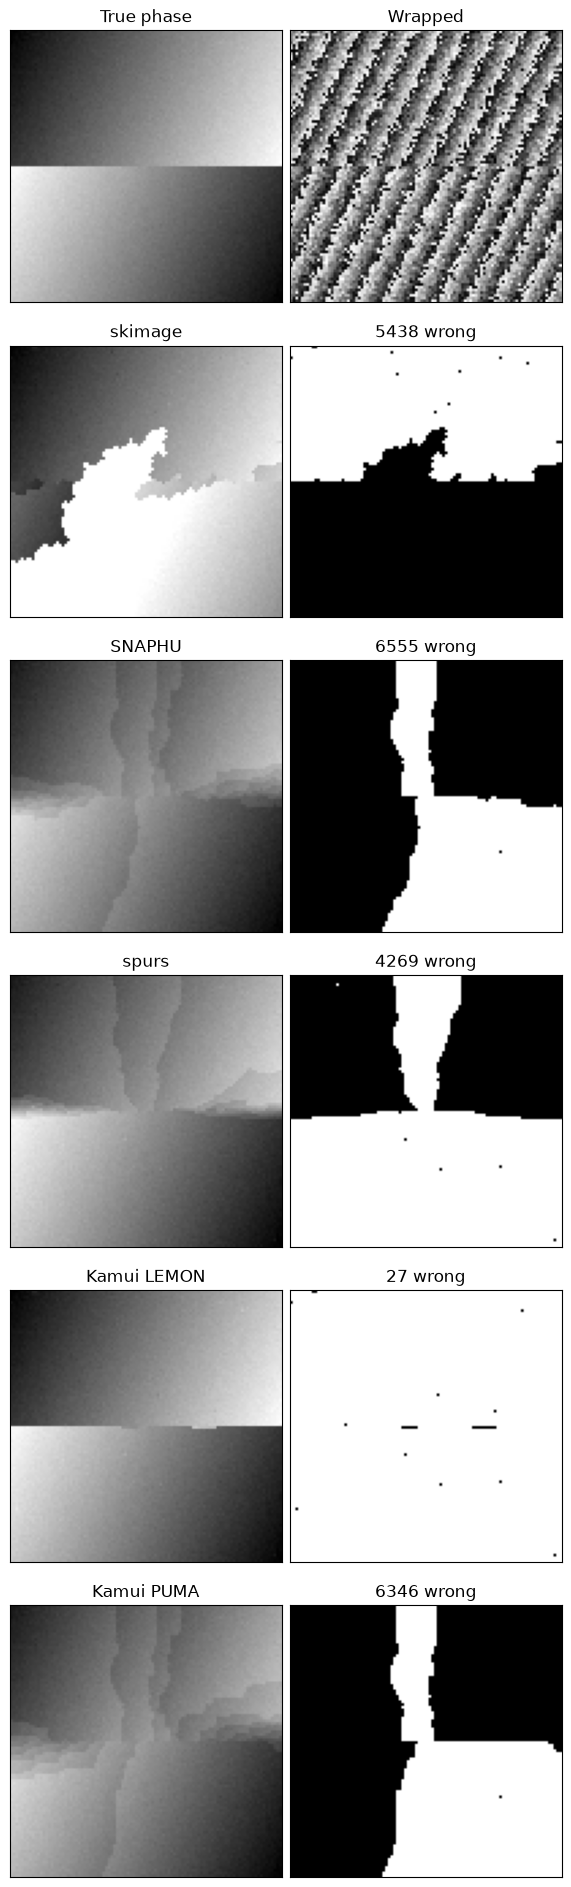

In [7]:
noisy_shear = shear + rng.normal(0, 0.125 * 2 * np.pi, shear.shape)
wrapped_noisy_shear = kamui.wrap_difference(noisy_shear)
noisy_shear_results = unwrap_all(wrapped_noisy_shear)

compare(noisy_shear, wrapped_noisy_shear, noisy_shear_results)

## Gaussian

A Gaussian of height $10\pi$ with its top-left quadrant cut away, which leaves cliffs higher than
$\pi$; then with noise of 0.12 periods.

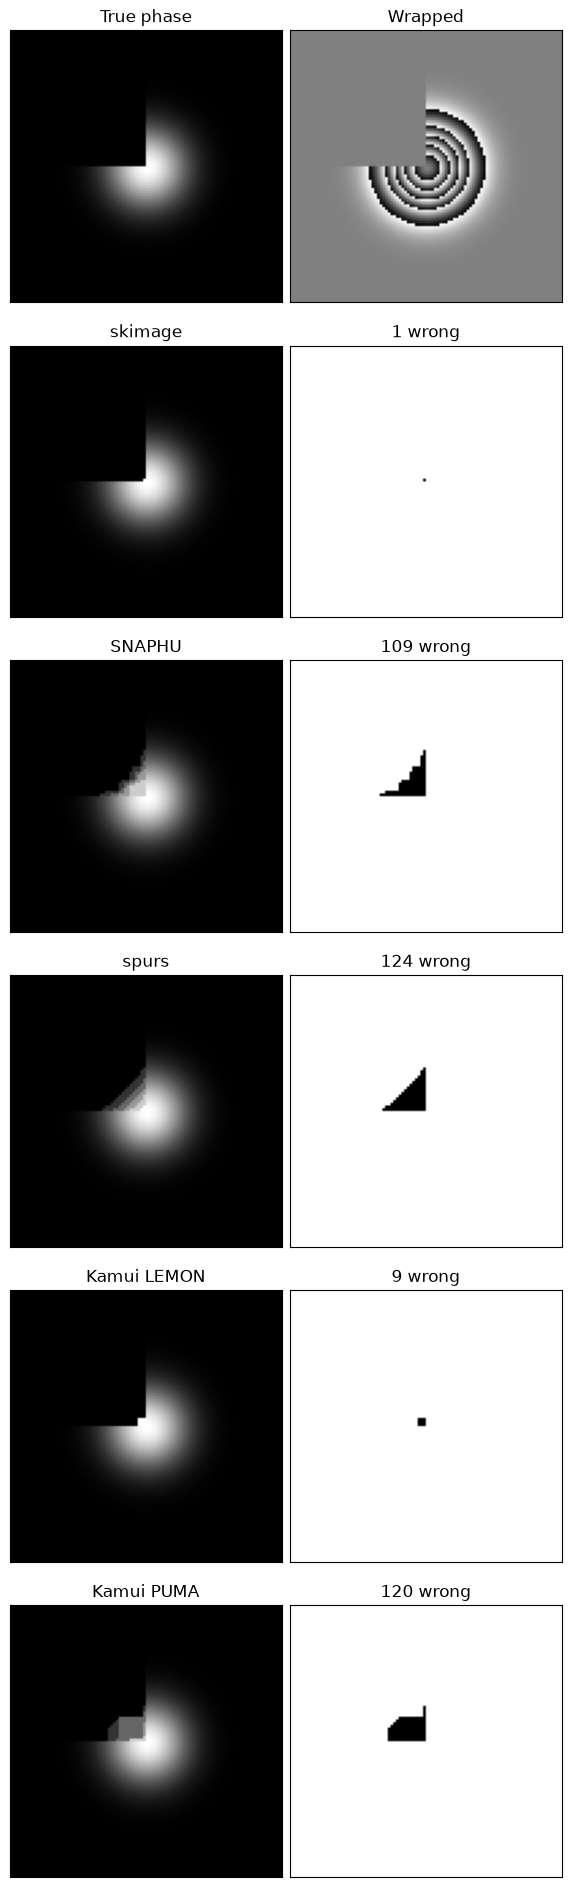

In [8]:
gauss = 10 * np.pi * np.exp(-0.5 * ((xx - N / 2) ** 2 + (yy - N / 2) ** 2) / (N / 10) ** 2)
gauss[: N // 2, : N // 2] = 0
wrapped_gauss = kamui.wrap_difference(gauss)

compare(gauss, wrapped_gauss, unwrap_all(wrapped_gauss))

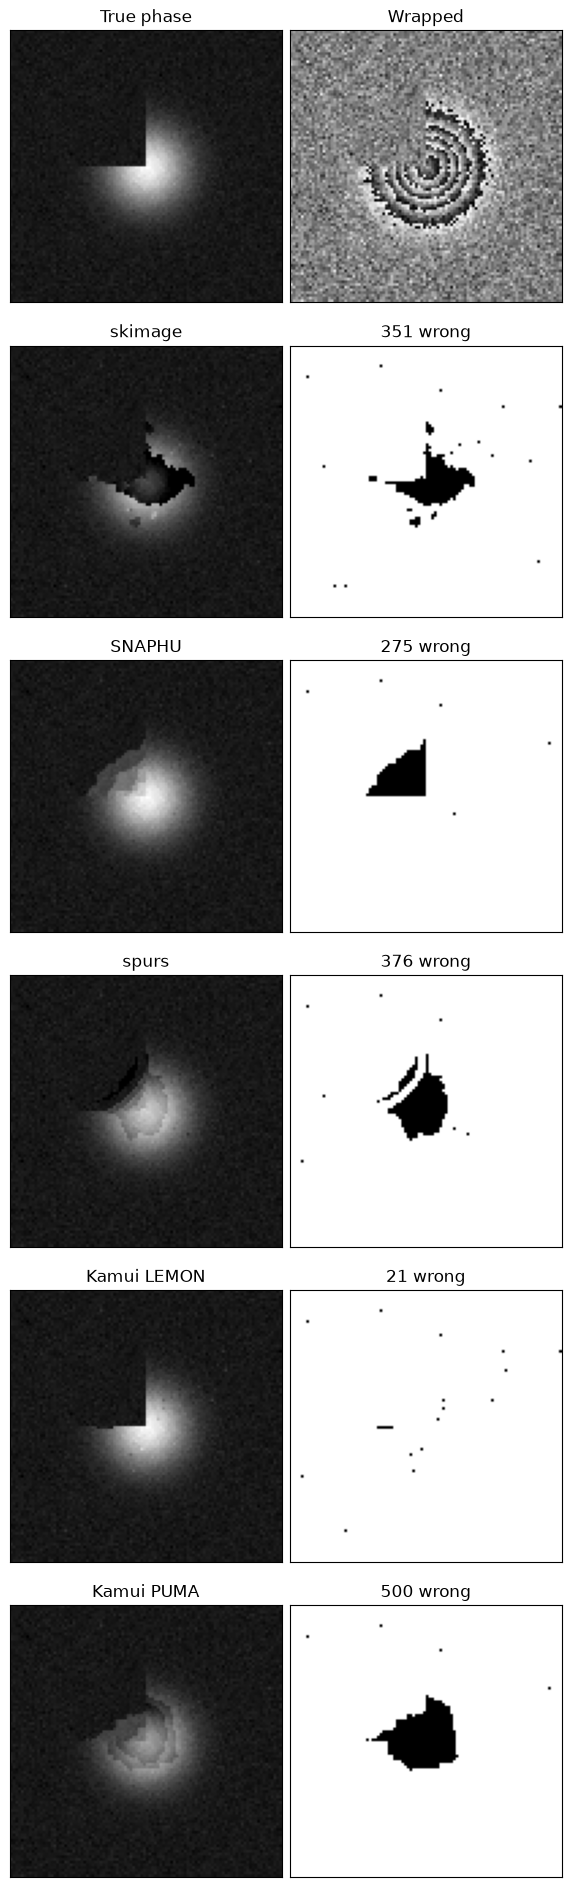

In [9]:
noisy_gauss = gauss + rng.normal(0, 0.12 * 2 * np.pi, gauss.shape)
wrapped_noisy_gauss = kamui.wrap_difference(noisy_gauss)
noisy_gauss_results = unwrap_all(wrapped_noisy_gauss)

compare(noisy_gauss, wrapped_noisy_gauss, noisy_gauss_results)

## Gaussian with Missing Data

The noisy Gaussian with its cut-away quadrant set to NaN. `unwrap_dimensional` drops the edges
that touch NaN pixels and returns NaN there; SNAPHU takes the same pixels as a mask.

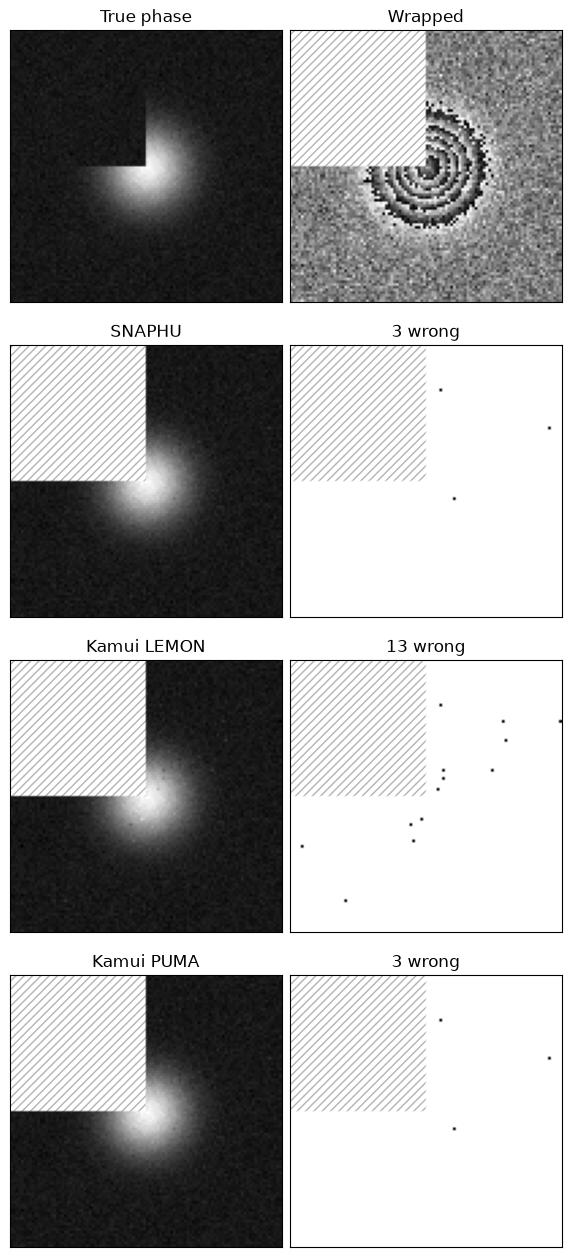

In [10]:
masked_noisy_gauss = wrapped_noisy_gauss.copy()
masked_noisy_gauss[: N // 2, : N // 2] = np.nan
# spurs takes no mask, and skimage's unwrap_phase does not return on NaN input.
masked_methods = {name: METHODS[name] for name in ("SNAPHU", "Kamui LEMON", "Kamui PUMA")}
masked_results = unwrap_all(masked_noisy_gauss, masked_methods)

compare(noisy_gauss, masked_noisy_gauss, masked_results)

## Weights

A plane wave crossed by a band of low coherence, with noise that grows as coherence drops. Kamui
gets the coherence as per-pixel `weights`, and SNAPHU as its coherence map. `return_info=True`
also returns Kamui's solver report.

integer weights: lemon, fractional weights: highs


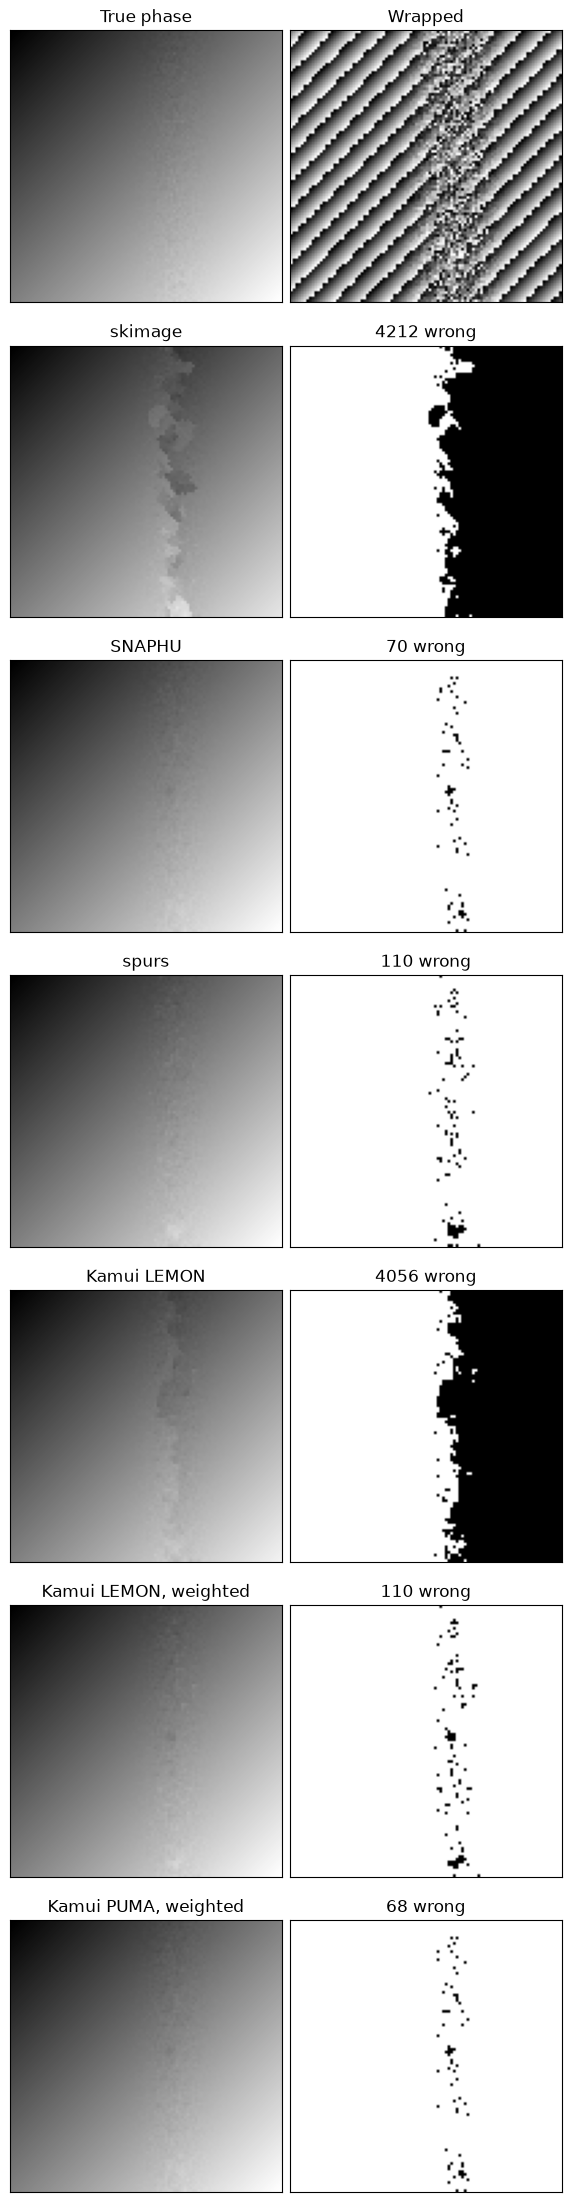

In [11]:
coherence = 1 - 0.85 * np.exp(-0.5 * ((xx - 60) / 8) ** 2)
noise_std = 0.25 * 2 * np.pi * (1 - coherence) / 0.85
# LEMON needs integer weights; fractional ones go to HiGHS. PUMA takes them as they are.
weights = np.round(coherence * 100)


def banded(seed):
    """Draw the plane wave with noise that grows as coherence drops."""
    return plane_wave + np.random.default_rng(seed).normal(0, noise_std)


banded_wave = banded(1)
wrapped_banded_wave = kamui.wrap_difference(banded_wave)
unweighted = kamui.unwrap_dimensional(wrapped_banded_wave)
weighted, info = kamui.unwrap_dimensional(wrapped_banded_wave, weights=weights, return_info=True)
_, fractional_info = kamui.unwrap_dimensional(
    wrapped_banded_wave, weights=coherence, return_info=True
)
print(f"integer weights: {info.solver}, fractional weights: {fractional_info.solver}")

compare(
    banded_wave,
    wrapped_banded_wave,
    {
        "skimage": unwrap_phase(wrapped_banded_wave),
        "SNAPHU": unwrap_snaphu(wrapped_banded_wave, coherence),
        "spurs": unwrap_spurs(wrapped_banded_wave),
        "Kamui LEMON": unweighted,
        "Kamui LEMON, weighted": weighted,
        "Kamui PUMA, weighted": kamui.unwrap_dimensional(
            wrapped_banded_wave, method="gc", weights=coherence
        ),
    },
)

Twelve more noise draws, with and without weights.

In [12]:
wrong = {"Kamui LEMON": [], "Kamui LEMON, weighted": []}
for seed in range(1, 13):
    truth = banded(seed)
    wrapped = kamui.wrap_difference(truth)
    wrong["Kamui LEMON"].append(n_errors(kamui.unwrap_dimensional(wrapped), truth))
    wrong["Kamui LEMON, weighted"].append(
        n_errors(kamui.unwrap_dimensional(wrapped, weights=weights), truth)
    )

for name, counts in wrong.items():
    sides_off = sum(count > N * N / 4 for count in counts)
    print(f"{name}: {np.mean(counts):.0f} wrong pixels on average, a side off in {sides_off} of 12")

Kamui LEMON: 1115 wrong pixels on average, a side off in 3 of 12
Kamui LEMON, weighted: 429 wrong pixels on average, a side off in 1 of 12


## Chelsea Cat

scikit-image's cat, scaled to $[0, 4\pi]$ and wrapped, with timings.

skimage took 0.04 s
SNAPHU took 0.93 s
spurs took 0.08 s
Kamui LEMON took 0.28 s
Kamui PUMA took 1.07 s


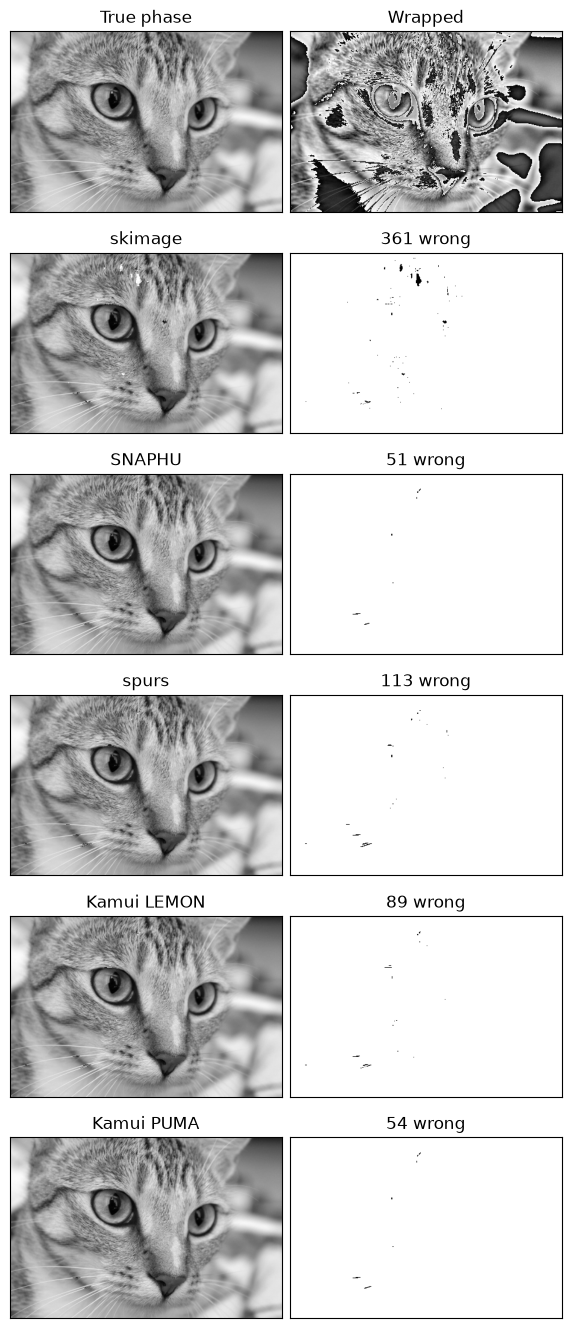

In [13]:
gray_cat = color.rgb2gray(img_as_float(data.chelsea()))
cat = exposure.rescale_intensity(gray_cat, out_range=(0, 4 * np.pi))
wrapped_cat = kamui.wrap_difference(cat)

cat_results = {}
for name, unwrap in METHODS.items():
    start = perf_counter()
    cat_results[name] = unwrap(wrapped_cat)
    print(f"{name} took {perf_counter() - start:.2f} s")

compare(cat, wrapped_cat, cat_results)

## Check

In [14]:
# CI executes this notebook; these asserts catch regressions.
for unwrapped in plane_results.values():
    assert n_errors(unwrapped, plane_wave) == 0
for name, unwrapped in shear_results.items():
    assert (n_errors(unwrapped, shear) == 0) == (name == "Kamui LEMON")
masked_gauss = np.where(np.isnan(masked_noisy_gauss), np.nan, wrapped_gauss)
for unwrapped in unwrap_all(masked_gauss, masked_methods).values():
    assert n_errors(unwrapped, gauss) == 0
    assert np.isnan(unwrapped[: N // 2, : N // 2]).all()
for name, unwrapped in noisy_gauss_results.items():
    if name != "Kamui LEMON":
        assert n_errors(noisy_gauss_results["Kamui LEMON"], noisy_gauss) < n_errors(
            unwrapped, noisy_gauss
        )
assert info.solver == "lemon" and fractional_info.solver == "highs"
assert np.mean(wrong["Kamui LEMON, weighted"]) < np.mean(wrong["Kamui LEMON"]) / 2
for name in ("Kamui LEMON", "Kamui PUMA"):
    assert n_errors(cat_results[name], cat) < 0.01 * cat.size